In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

In [2]:
df=pd.read_csv(r"C:\Users\CHAIT\OneDrive\Desktop\ML_git_hub\california_housing.csv")

In [3]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
x=df[['MedInc']]
y=df['MedHouseVal']

In [10]:
degree=[1,2,3,4,5,6,7,8,9]

In [11]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [12]:
train_err=[]
test_err=[]

In [13]:
for d in degree:
    p=PolynomialFeatures(degree=d)
    x_train_poly=p.fit_transform(x_train)
    x_test_poly=p.transform(x_test)
    model=LinearRegression()
    model.fit(x_train_poly,y_train)
    mse_train=mean_squared_error(y_train,model.predict(x_train_poly))
    mse_test=mean_squared_error(y_test,model.predict(x_test_poly))
    train_err.append(mse_train)
    test_err.append(mse_test)
    print('-'*20)
    print('Degree= ',d)
    print('Train error= ',train_err[-1])
    print('Test error= ',test_err[-1])
    print()

--------------------
Degree=  1
Train error=  0.6991447170182823
Test error=  0.7091157771765549

--------------------
Degree=  2
Train error=  0.6929887977115864
Test error=  0.7032732680932144

--------------------
Degree=  3
Train error=  0.6806795207431472
Test error=  0.6982964744960336

--------------------
Degree=  4
Train error=  0.6805417816982363
Test error=  0.6981042443894433

--------------------
Degree=  5
Train error=  0.6803681446810634
Test error=  0.6987158425289234

--------------------
Degree=  6
Train error=  0.6788430149294993
Test error=  0.6959703899346835

--------------------
Degree=  7
Train error=  0.6761239191210887
Test error=  0.6931443807682218

--------------------
Degree=  8
Train error=  0.6759395352014229
Test error=  0.6926991024133982

--------------------
Degree=  9
Train error=  0.6763619700441673
Test error=  0.6934360034815659



In [15]:
import matplotlib.pyplot as plt

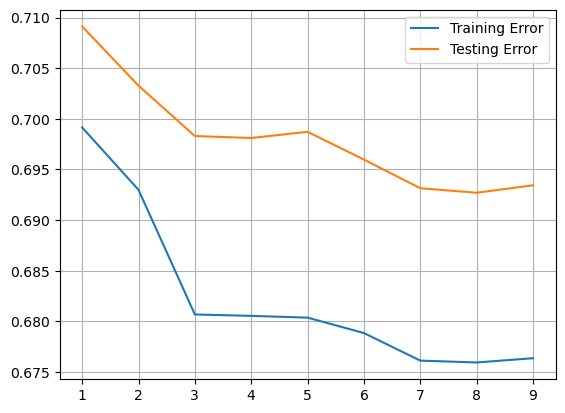

In [19]:
plt.plot(degree,train_err,label='Training Error')
plt.plot(degree,test_err,label='Testing Error')
plt.legend()
plt.grid()